# Urban change detection with Sentinel-2 and deep learning

**Final-year project showcase · OSCD benchmark**

We compare a spectral rule, an early-fusion U-Net and a Siamese U-Net on human-labeled urban change. The task includes roads and buildings; it does **not** specifically identify vegetation-to-built-up conversion. This notebook reads committed result tables, so you can present it without retraining.

**Presentation route:** problem → data split → model ideas → pooled results → city failures → honest conclusion.

## 1. What is the model asked to do?

Each sample contains two aligned six-band Sentinel-2 views of the same place. The output is a binary pixel mask: change or no change. We trained on ten cities, selected checkpoints on four different cities, and measured results on ten official test cities. Entire cities, rather than random pixels, form each split to make the transfer question meaningful.

**Models:** Early fusion stacks the two dates as twelve input channels. The Siamese network encodes each date with shared weights, then compares their feature maps. A six-band root-mean-square spectral difference is the simple baseline.

## 2. Pooled test results

Precision asks *of the pixels flagged, how many really changed?* Recall asks *of the changes, how many were found?* F1 combines those two. The table below is micro-aggregated across the evaluated test chips; it does not show whether every city performs equally well.

In [1]:
import pandas as pd
from pathlib import Path
data = pd.read_csv(Path('../paper/data/oscd_city_metrics.csv'))
first = data[data.model.isin(['change_vector', 'unet', 'original_20261102'])]
totals = first.groupby('model')[['tp', 'fp', 'fn', 'tn']].sum()
totals['precision'] = totals.tp / (totals.tp + totals.fp)
totals['recall'] = totals.tp / (totals.tp + totals.fn)
totals['f1'] = 2 * totals.precision * totals.recall / (totals.precision + totals.recall)
table = totals[['precision', 'recall', 'f1']].rename(index={
    'change_vector': 'Spectral change vector', 'unet': 'Early U-Net',
    'original_20261102': 'Siamese U-Net'})
table.round(3)

,precision,recall,f1
model,,,
Spectral change vector,0.312,0.418,0.357
Siamese U-Net,0.404,0.556,0.468
Early U-Net,0.644,0.305,0.414


The first Siamese run finds more true changes than early fusion but makes more false alarms. Across three seeds its mean F1 is 0.412, so the first run's 0.468 must not be presented as a stable expected score. A conservative loss setting averages F1 0.441 over three seeds, with higher precision and lower recall.

## 3. Does it generalize to each city?

The figure shows per-city F1. The Siamese columns average three seeds for each setting. The percentage beside each city is the fraction of evaluated pixels annotated as change.

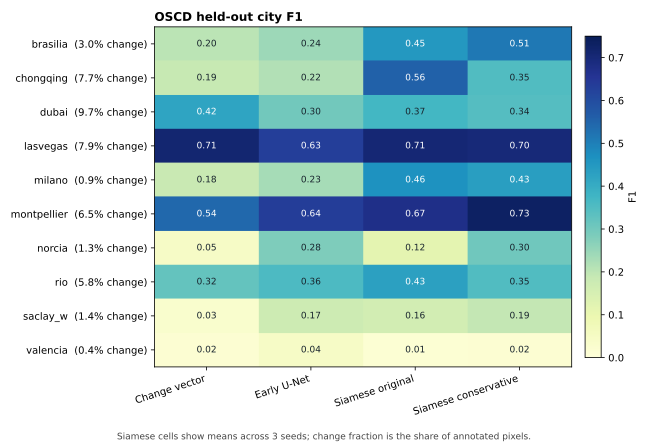

In [2]:
from IPython.display import SVG, display
display(SVG(filename='../paper/figures/oscd_city_f1.svg'))

**What to point out:** Montpellier and Las Vegas have substantially stronger results than Valencia. Valencia contains very little annotated change (0.37% of evaluated pixels), but prevalence alone has not been proven to cause the failure. This is why the pooled F1 cannot stand in for performance everywhere.

## 4. What does one prediction look like?

This fixed Abu Dhabi **validation** chip has visible change. The two model panels display probabilities, while the human mask is binary. It was selected as an illustration and does not estimate test accuracy.

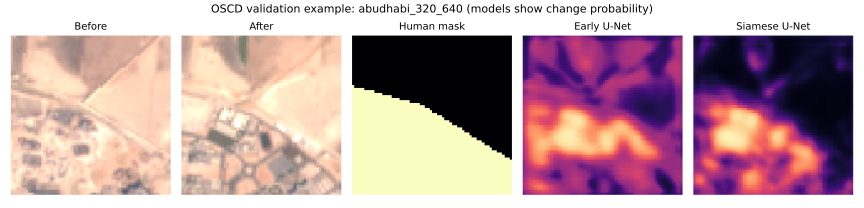

In [3]:
display(SVG(filename='../paper/figures/oscd_validation_example.svg'))

## 5. What can we conclude?

- The supervised models beat our simple spectral baseline in the first pooled run.
- More recall can come with many more false alarms. Reducing positive-class emphasis raises precision but lowers recall across the three paired seeds.
- Transfer varies widely by city; the method is not ready for operational mapping.
- Later model settings were explored after the first official test result was viewed. The follow-up is exploratory, and an untouched confirmatory evaluation is required for a stronger journal claim.

**To reproduce:** see the repository README, `docs/oscd_benchmark.md`, and `docs/oscd_weight_sensitivity.md`. The interactive companion dashboard is `dashboard/index.html`.